# 

# Example of the aitlas toolbox in the context of object detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import AUAIRDataset
from aitlas.models import FasterRCNN
from aitlas.transforms import Resize
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/au-air/auair2019data/images",
    "annotation_dir": "./data/au-air/auair2019annotations/annotations.json",
}
dataset = AUAIRDataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 32823


## Show images from the dataset

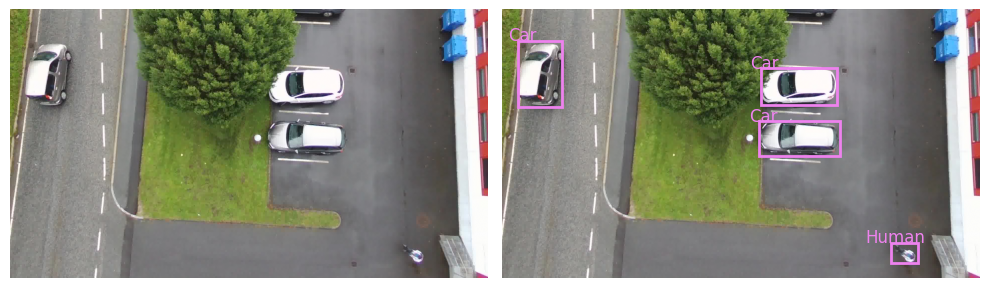

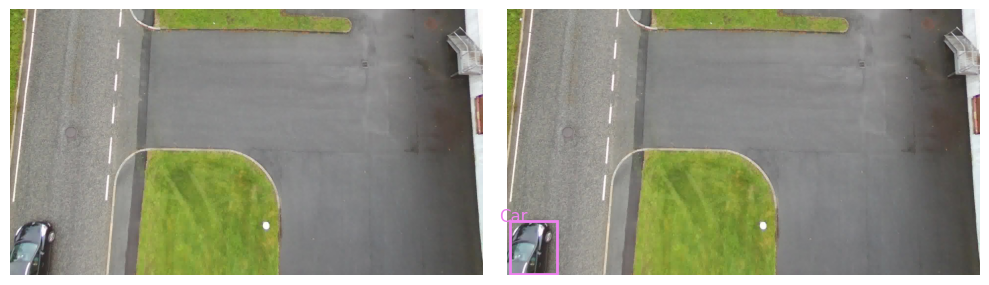

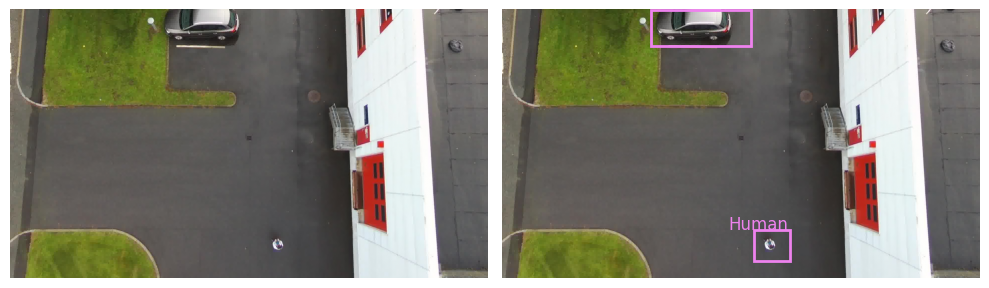

In [8]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(200)

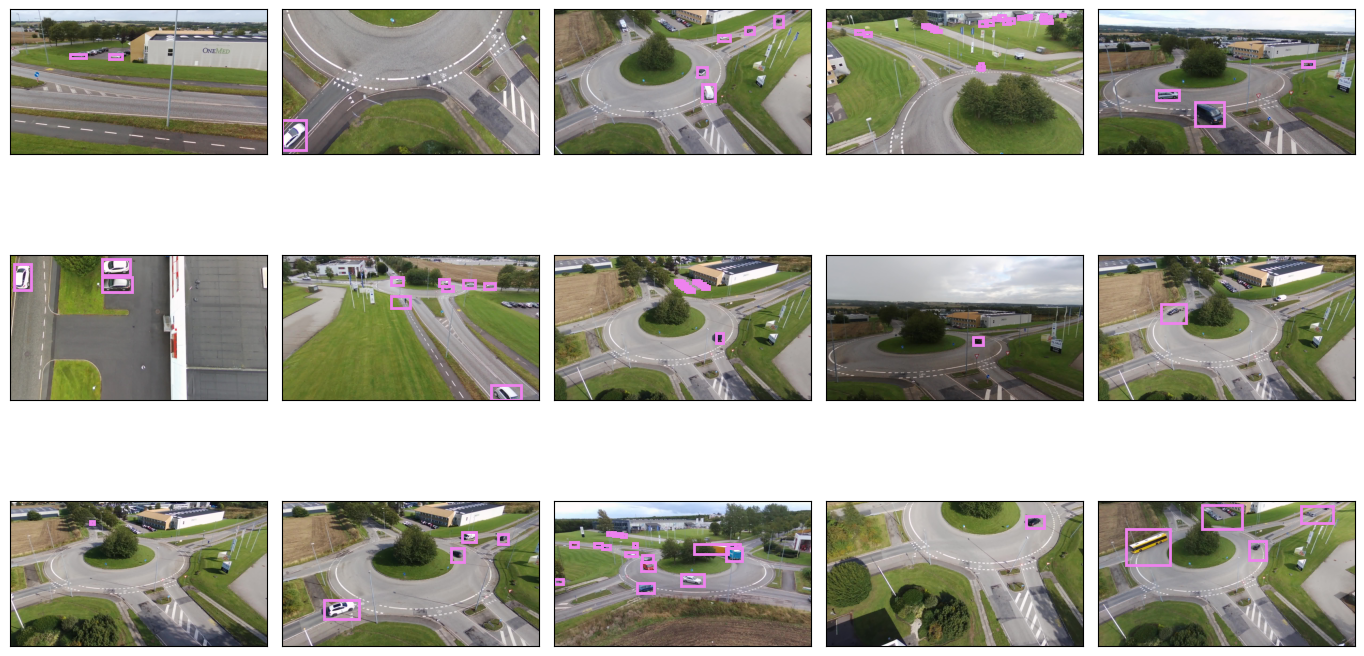

In [4]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [5]:
dataset.data_distribution_table()

,Label,Count
0,Car,102619
1,Van,9995
2,Truck,9545
3,Human,5158
4,Trailer,2538
5,Bicycle,1128
6,Bus,729
7,Motorbike,319


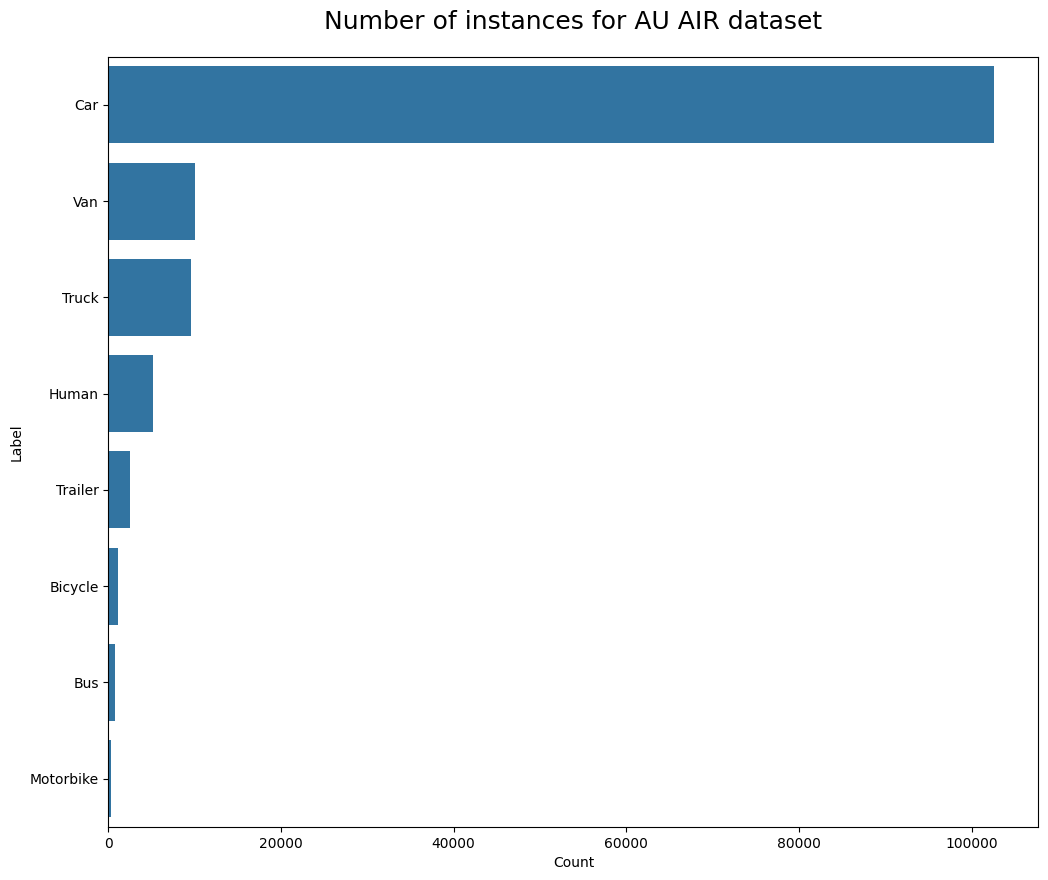

In [6]:
fig = dataset.data_distribution_barchart()

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "data_dir": "./data/au-air/auair2019data/images",
    "annotation_dir": "./data/au-air/auair2019annotations/annotations.json",
    "csv_file": "./data/au-air/auair2019data/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = AUAIRDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 26259


## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/auair/"
model_config = {
    "num_classes": 8,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Training 

In [15]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-07-16 13:49:35,055 INFO Starting training.
training: 100%|██████████| 1642/1642 [59:38<00:00,  2.18s/it]
2025-07-16 14:49:13,523 INFO epoch: 1, time: 3578, loss:  0.55024
testing on train set: 100%|██████████| 1642/1642 [1:02:24<00:00,  2.28s/it]
2025-07-16 15:53:12,401 INFO map:0.10144302994012833, map_50:0.26155999302864075, map_75:0.05785035341978073, map_small:0.049762703478336334, map_medium:0.11651049554347992, map_large:0.13521888852119446, mar_1:0.16139042377471924, mar_10:0.1991957575082779, mar_100:0.20210467278957367, mar_small:0.13495634496212006, mar_medium:0.21932338178157806, mar_large:0.19930347800254822, map_per_class:tensor(0.), tensor(0.1398), tensor(0.2173), tensor(0.1458), tensor(0.0438), tensor(0.0283), tensor(0.2219), tensor(0.0146), mar_100_per_class:tensor(0.), tensor(0.2852), tensor(0.3844), tensor(0.2771), tensor(0.1467), tensor(0.1251), tensor(0.3405), tensor(0.0578), classes:tensor(0, dtype=torch.int32), tensor(1, dtype=torch.int32), tensor(2, dtype=to

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/au-air/auair2019data/images",
    "annotation_dir": "./data/au-air/auair2019annotations/annotations.json",
    "csv_file": "./data/au-air/auair2019data/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = AUAIRDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/auair/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 3282


2025-07-17 09:55:05,589 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/auair/checkpoint.pth.tar
2025-07-17 09:55:05,986 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/auair/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 411/411 [06:57<00:00,  1.02s/it]


[{'map': 0.0912042036652565,
  'map_50': 0.2282291054725647,
  'map_75': 0.06343892961740494,
  'map_small': 0.04709358513355255,
  'map_medium': 0.14014220237731934,
  'map_large': 0.15993258357048035,
  'mar_1': 0.14342109858989716,
  'mar_10': 0.17339171469211578,
  'mar_100': 0.1755879670381546,
  'mar_small': 0.10998247563838959,
  'mar_medium': 0.22960184514522552,
  'mar_large': 0.22280734777450562,
  'map_per_class': [tensor(0.),
   tensor(0.1042),
   tensor(0.1306),
   tensor(0.0990),
   tensor(0.1174),
   tensor(0.0174),
   tensor(0.2390),
   tensor(0.0220)],
  'mar_100_per_class': [tensor(0.),
   tensor(0.2456),
   tensor(0.2856),
   tensor(0.2038),
   tensor(0.1760),
   tensor(0.0808),
   tensor(0.3182),
   tensor(0.0947)],
  'classes': [tensor(0, dtype=torch.int32),
   tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32),
   tensor(5, dtype=torch.int32),
   tensor(6, dtype=torch.int32),
   tensor(7,

## Predictions

2025-07-17 10:02:14,250 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/auair/checkpoint.pth.tar
2025-07-17 10:02:14,837 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/auair/checkpoint.pth.tar at epoch 11


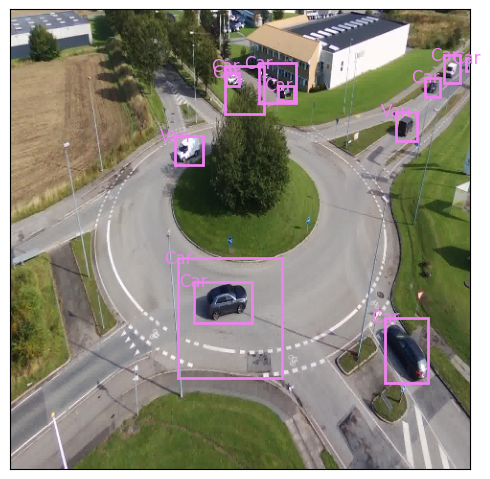

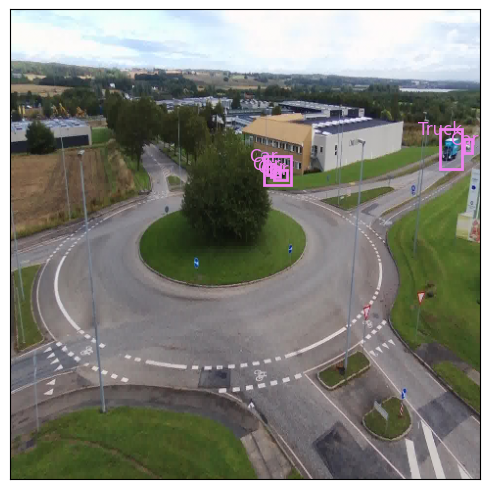

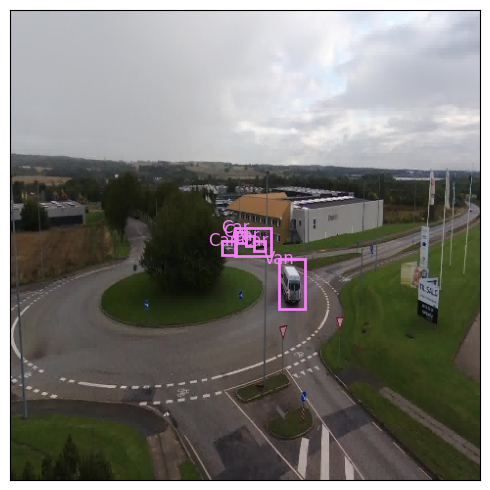

In [ ]:
model_config = {
    "num_classes": 8,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/auair/checkpoint.pth.tar"
labels = ['Human', 'Car', 'Truck', 'Van', 'Motorbike', 'Bicycle', 'Bus', 'Trailer']
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/au-air/auair2019data/images/frame_20190905103112_x_0005043.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/au-air/auair2019data/images/frame_20190905091750_xx_0000746.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/au-air/auair2019data/images/frame_20190905091750_x_0000987.jpg')
fig = model.detect_objects(image, labels, transform)